In [1]:
import sys
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [6]:
sys.path.insert(0, str(Path.cwd().parent))

from src.data_loader import load_data

df_train, df_test = load_data()

To prevent data leakage from the test set to the train set, we avoid testing our baseline model on the final test set. 

Let us first try to find whether regularization coefficients have a substantial effect on the logisitic regression model.

To do so, we will perform a grid search.

In [87]:
from src.preprocessing import prepare_data, build_preprocessor

X_train, y_train = prepare_data(df_train)

preprocessor = build_preprocessor(X_train)

logistic_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

param_grid = {"model__C": 
              [0.001, 0.01, 0.1, 1, 2, 5, 10, 15, 20, 25, 30, 35, 45, 50, 55]
              }
grid = GridSearchCV(logistic_pipeline, 
                    param_grid, 
                    scoring="accuracy", 
                    cv=5, 
                    return_train_score=True
                    )
grid.fit(X_train, y_train)

,estimator,Pipeline(step..._iter=2000))])
,param_grid,"{'model__C': [0.001, 0.01, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,transformers,"[('scaler', ...), ('binary', ...)]"


In [88]:
print(f"The best score reached across these different values of C is {grid.best_score_}, with C={grid.best_params_["model__C"]}")

The best score reached across these different values of C is 0.7037029166481606, with C=50


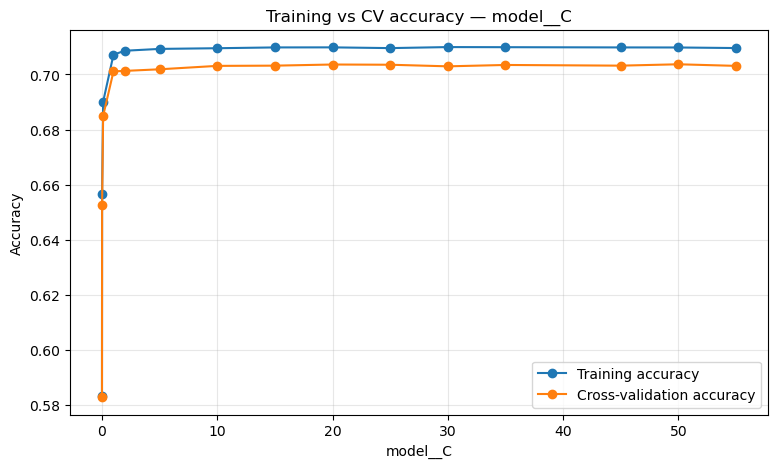

In [89]:
from src.vizualization import plot_hyperparam

plot_hyperparam(grid.cv_results_, param_name="model__C", fixed_params=None)

The higher C, the less L2 regularized are the coefficients. We see that here, regularization has very little impact on the performance of the model on the cross-validation set. Whatever the hyperparameter, performance remains still much lower than the one of a baseline non-linear model like a Decision Tree. We can thus suppose that this dataset probably contains non-linearities or interactions that a linear model cannot learn.  

To identify the optimal hyperparameters for our Decision Tree while limiting selection biais from repeatedly evaluating models on the test set, we perform a 5-fold cross-validation to evaluate model performance on unseen validation folds.

In [99]:
tree_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(criterion='gini', random_state=42))
])

param_grid = {"model__max_depth": [1, 2, 5, 10, 15, 20, 25, 30, 40]}

grid = GridSearchCV(
    tree_pipeline,
    param_grid,
    scoring="accuracy",
    cv=5,
    return_train_score=True    
)

grid.fit(X_train, y_train)

print(f"The optimal maximum depth is {grid.best_params_['model__max_depth']}, with a mean cross-validation accuracy of {grid.best_score_}")



The optimal maximum depth is 15, with a mean cross-validation accuracy of 0.7751322348214378


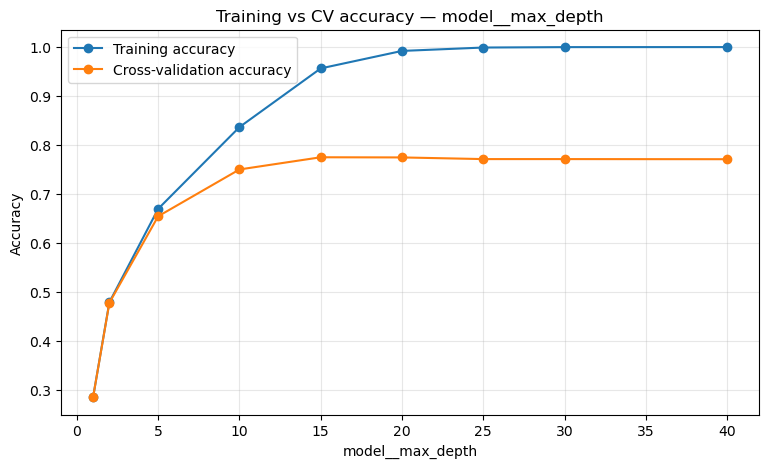

In [100]:
plot_hyperparam(grid.cv_results_, param_name="model__max_depth", fixed_params=None)

Among the maximum tree depths evaluated, a depth of 15 achieves the highest mean cross-validation accuracy, approximately 77.5%.

The curves show that validation accuracy initially increases with tree depth, before slightly decreasing and eventually stabilizing. Meanwhile, training accuracy continues to increase until it reaches 100%, suggesting that the tree becomes sufficiently flexible to memorize the training observations, potentially including noise.

Beyond a maximum depth of approximately 25, both training and validation accuracies plateau. This suggests that allowing additional depth no longer meaningfully changes the model's predictions, potentially because the trees have already reached their natural stopping conditions (leaf node impurity of 0).

These results illustrate the trade-off between model complexity and generalization: increasing tree depth improves the fit to the training data, but does not necessarily improve performance on unseen observations, or can even decrease it.

In [101]:
X_test, y_test = prepare_data(df_test)

y_test_pred = grid.best_estimator_.predict(X_test)

print(f"On the test set, the accuracy score reaches {accuracy_score(y_test, y_test_pred)}")

On the test set, the accuracy score reaches 0.781084656084656


In [102]:
rf = RandomForestClassifier(
    n_estimators=100, 
    criterion="gini")


rf_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(criterion="gini", random_state=42))
])

param_grid = {"model__n_estimators": [10, 100, 200, 300, 500, 1000]}

grid = GridSearchCV(
    rf_pipeline,
    param_grid,
    scoring="accuracy",
    cv=5,
    return_train_score=True    
)

grid.fit(X_train, y_train)

print(f"The optimal maximum depth is {grid.best_params_['model__n_estimators']}, with a mean cross-validation accuracy of {grid.best_score_}")



The optimal maximum depth is 200, with a mean cross-validation accuracy of 0.8565641153539986


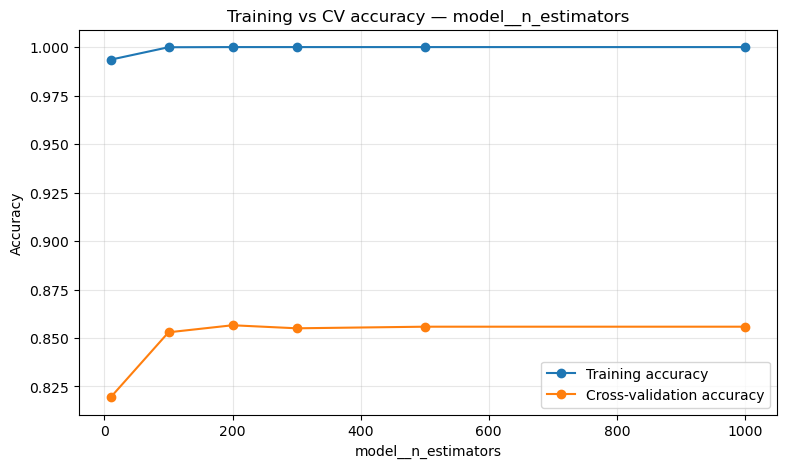

In [ ]:
plot_hyperparam(grid.cv_results_, param_name="model__n_estimators", fixed_params=None)